In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score


In [ ]:
# Load the dataset
df = pd.read_csv("/content/breast-cancer.csv")

# Display first five records
print("First Five Records:")
print(df.head())

print("\n" + "=" * 60)

First Five Records:
     age mefalsepause tumor-size inv-falsedes falsede-caps  deg-malig breast  \
0  40-49   premefalse      15-19          0-2         True          3  right   
1  50-59         ge40      15-19          0-2        False          1  right   
2  50-59         ge40      35-39          0-2        False          2   left   
3  40-49   premefalse      35-39          0-2         True          3  right   
4  40-49   premefalse      30-34          3-5         True          2   left   

  breast-quad  irradiat                    class  
0     left_up     False        recurrence-events  
1     central     False  false-recurrence-events  
2    left_low     False        recurrence-events  
3    left_low      True  false-recurrence-events  
4    right_up     False        recurrence-events  



In [ ]:
# Display dataset information
print("Dataset Information:")
print(df.info())

print("\n" + "=" * 60)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 272 entries, 0 to 271
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   age           272 non-null    object
 1   mefalsepause  272 non-null    object
 2   tumor-size    272 non-null    object
 3   inv-falsedes  272 non-null    object
 4   falsede-caps  264 non-null    object
 5   deg-malig     272 non-null    int64 
 6   breast        272 non-null    object
 7   breast-quad   271 non-null    object
 8   irradiat      272 non-null    bool  
 9   class         272 non-null    object
dtypes: bool(1), int64(1), object(8)
memory usage: 19.5+ KB
None



In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

print("\n" + "=" * 60)

Missing Values:
age             0
mefalsepause    0
tumor-size      0
inv-falsedes    0
falsede-caps    8
deg-malig       0
breast          0
breast-quad     1
irradiat        0
class           0
dtype: int64



In [ ]:
# Display descriptive statistics of numerical attributes
print("Descriptive Statistics:")
print(df.describe())

print("\n" + "=" * 60)



Descriptive Statistics:
        deg-malig
count  272.000000
mean     2.058824
std      0.736649
min      1.000000
25%      2.000000
50%      2.000000
75%      3.000000
max      3.000000



In [ ]:
# Display distribution of diagnosis classes
print("Diagnosis Class Distribution:")
print(df["class"].value_counts())

Diagnosis Class Distribution:
class
false-recurrence-events    191
recurrence-events           81
Name: count, dtype: int64


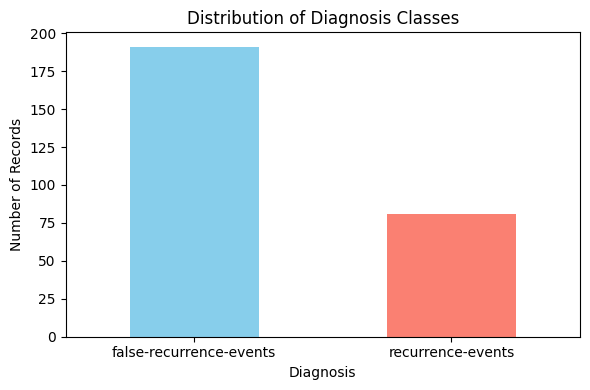

In [ ]:
# Plot diagnosis distribution
plt.figure(figsize=(6, 4))
df["class"].value_counts().plot(
    kind="bar",
    color=["skyblue", "salmon"]
)

plt.title("Distribution of Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Handle missing values by imputing with the mode for categorical columns
for col in ['falsede-caps', 'breast-quad']:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
age             0
mefalsepause    0
tumor-size      0
inv-falsedes    0
falsede-caps    0
deg-malig       0
breast          0
breast-quad     0
irradiat        0
class           0
dtype: int64


/tmp/ipykernel_496/2743948688.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mode_val, inplace=True)
/tmp/ipykernel_496/2743948688.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col].fillna(mode_val, inplace=True)


In [ ]:
# Convert categorical features to numerical using one-hot encoding
df_encoded = pd.get_dummies(df.drop('class', axis=1), drop_first=True)

# Separate features (X) and target variable (y)
X = df_encoded
y = df['class']

print("Shape of features (X):", X.shape)
print("Shape of target (y):", y.shape)
print("\nFirst 5 rows of encoded features:")
print(X.head())

Shape of features (X): (272, 31)
Shape of target (y): (272,)

First 5 rows of encoded features:
   falsede-caps  deg-malig  irradiat  age_30-39  age_40-49  age_50-59  \
0          True          3     False      False       True      False   
1         False          1     False      False      False       True   
2         False          2     False      False      False       True   
3          True          3      True      False       True      False   
4          True          2     False      False       True      False   

   age_60-69  age_70-79  mefalsepause_lt40  mefalsepause_premefalse  ...  \
0      False      False              False                     True  ...   
1      False      False              False                    False  ...   
2      False      False              False                    False  ...   
3      False      False              False                     True  ...   
4      False      False              False                     True  ...   

   inv-f

In [ ]:
# Split the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (217, 31)
X_test shape: (55, 31)
y_train shape: (217,)
y_test shape: (55,)


In [ ]:
# Implement a Decision Tree Classifier with a specified maximum depth
# Let's start with max_depth=3 for better visualization
dt_classifier = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_classifier.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully.")

Decision Tree Classifier trained successfully.


In [ ]:
# Predict the diagnosis of the test data
y_pred = dt_classifier.predict(X_test)

# Calculate the classification accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Classification Accuracy: {accuracy:.4f}")

Classification Accuracy: 0.6909


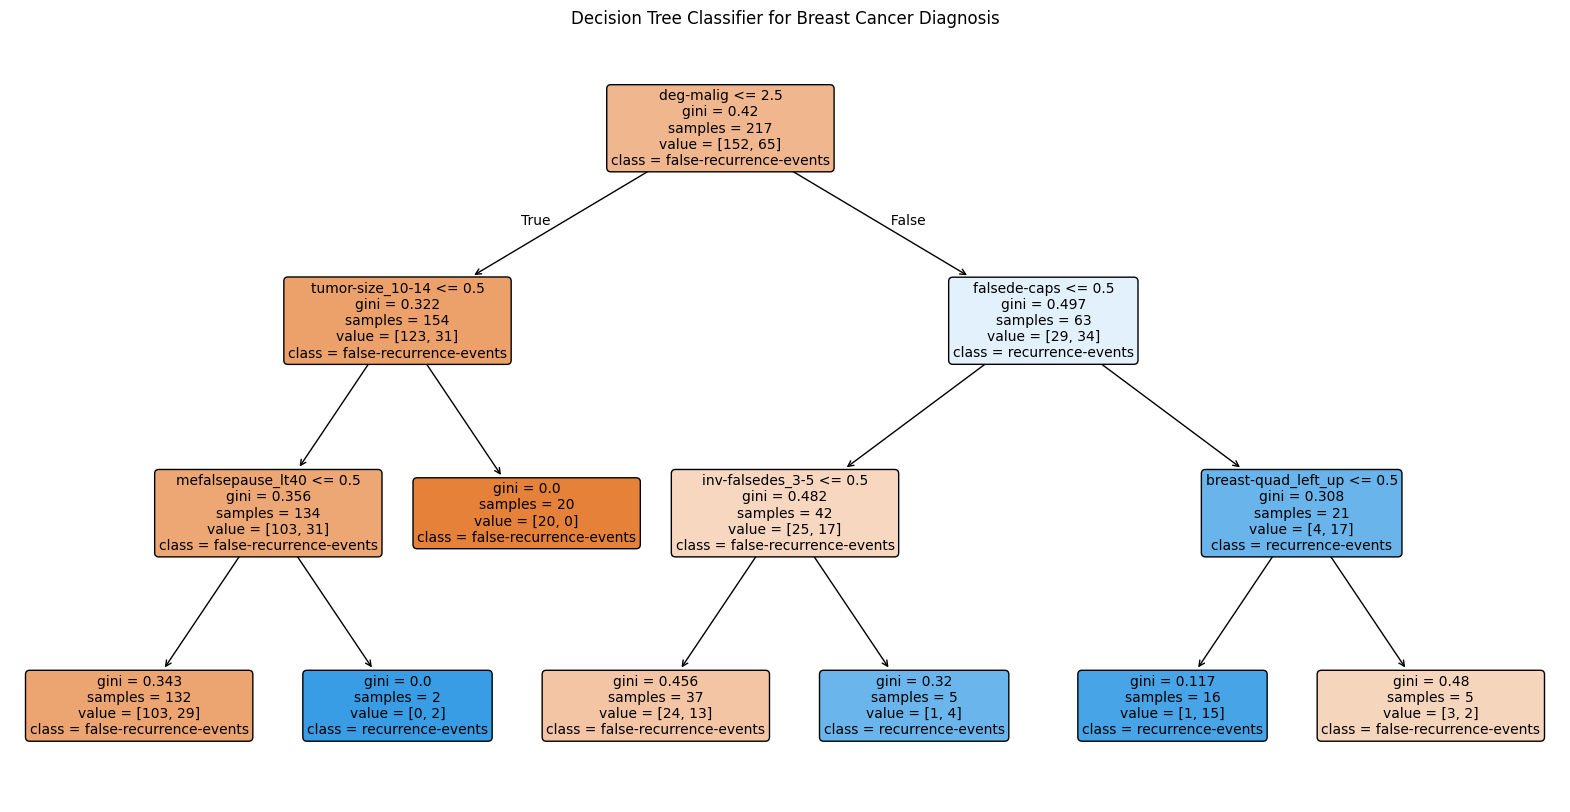

In [ ]:
# Plot and display the resulting Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_classifier,
    feature_names=X.columns.tolist(),
    class_names=dt_classifier.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classifier for Breast Cancer Diagnosis')
plt.show()